# A. DATA PREPARATION

A1. Import dataset

In [101]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

A2. Menambahkan datasest

In [102]:
df = pd.read_csv('drug200.csv')

A3. Melihat 5 data teratas

In [103]:
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY


A4. Melihat deskripsi data

In [104]:
df.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


Hasil dari yang ada di atas :
- Rata-rata umur yang ada di atas ada di 44 Tahun / Paruh Baya, Hal ini mengindikasikan bahwa data di dominasi oleh kelompok usia Paruh Baya.
- Fitur Na-to_K memiliki nilai standar defiasi yang cukup besar terhadap nilai rata-rata, Hal ini mengindikasikan fitur ini dapat menjadi faktor pembeda untuk klasifikasi jenis obat.

A5. Melihat informasi data

In [105]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    str    
 2   BP           200 non-null    str    
 3   Cholesterol  200 non-null    str    
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


Dari hasil di atas :
- Ada 200 baris dengan 6 kolom
- Ada tipe data float, int, dan str

A6. Melihat data kosong

In [106]:
df.isna().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

Dari hasil di atas tidak ada data kosong

A7. Melihat duplikasi data

In [107]:
def cek_duplikat(df):
    duplicated_df = df[df.duplicated()].sum()
    index_list = duplicated_df.index.tolist()
    print ('Data yang terindikasi duplikat :')
    print (duplicated_df)
    print (f'Baris : {index_list}')

In [108]:
cek_duplikat(df)

Data yang terindikasi duplikat :
Age              0
Sex               
BP                
Cholesterol       
Na_to_K        0.0
Drug              
dtype: object
Baris : ['Age', 'Sex', 'BP', 'Cholesterol', 'Na_to_K', 'Drug']


Dari hasil di atas tidak terindikasi data duplikat

A8. Melihat isi dari kolom BP (Blood Presure)

In [109]:
df['BP'].unique()

<StringArray>
['HIGH', 'LOW', 'NORMAL']
Length: 3, dtype: str

A9. Melihat isi dari kolom Cholesterol

In [110]:
df['Cholesterol'].unique()

<StringArray>
['HIGH', 'NORMAL']
Length: 2, dtype: str

A10. Melakukan One Hot Encoding

In [111]:
# One hot encoding
df_encode = pd.get_dummies(df, columns= ['BP', 'Cholesterol'], dtype=int)

In [112]:
df_encode.head()

,Age,Sex,Na_to_K,Drug,BP_HIGH,BP_LOW,BP_NORMAL,Cholesterol_HIGH,Cholesterol_NORMAL
0,23,F,25.355,drugY,1,0,0,1,0
1,47,M,13.093,drugC,0,1,0,1,0
2,47,M,10.114,drugC,0,1,0,1,0
3,28,F,7.798,drugX,0,0,1,1,0
4,61,F,18.043,drugY,0,1,0,1,0


Kami melakukan One Hot Encoding agar dapat menggunakan model Decision Tree (Mengubahnya menjadi Binary)

A11. Melihat data dari kolom Drug

In [113]:
df_encode['Drug'].unique()

<StringArray>
['drugY', 'drugC', 'drugX', 'drugA', 'drugB']
Length: 5, dtype: str

In [114]:
df_encode['Drug'] = df['Drug'].replace({
    'drugA': '1',
    'drugB': '2',
    'drugC': '3',
    'drugX': '4',
    'drugY': '5',
})

Kami melakukan encoding fitur label menjadi numerik

A12. Melihat data dari kolom sex

In [115]:
df_encode['Sex'].unique()

<StringArray>
['F', 'M']
Length: 2, dtype: str

In [116]:
df_encode['Sex'] = df['Sex'].replace({
    'F': '1',
    'M': '2',
})

# B. EDA

B1. Menamplikan Plot distribusi Drug berdasarkan BP (Blood Presure)

<Axes: xlabel='count', ylabel='Drug'>

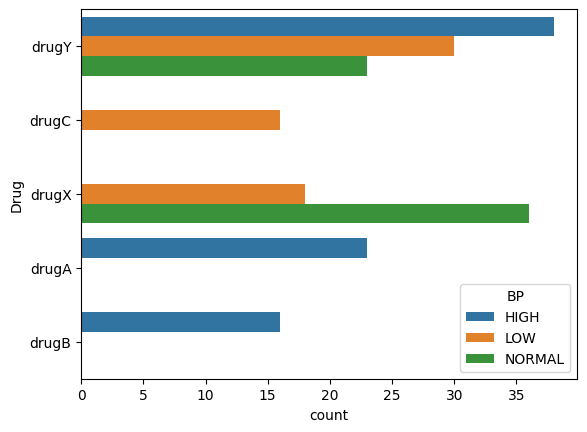

In [117]:
sns.countplot(data=df, y='Drug', hue='BP')

Berdasarkan hasil di atas:
- Drug A, B, Y Memiliki BP yang mendominasi HIGH
- Drug C Hanya memiliki BP LOW
- Drug X Memiliki BP dari LOW hingga NORMAL

B2. Menampilkan Plot Distribusi Drug berdasarkan Cholesterol

<Axes: xlabel='count', ylabel='Drug'>

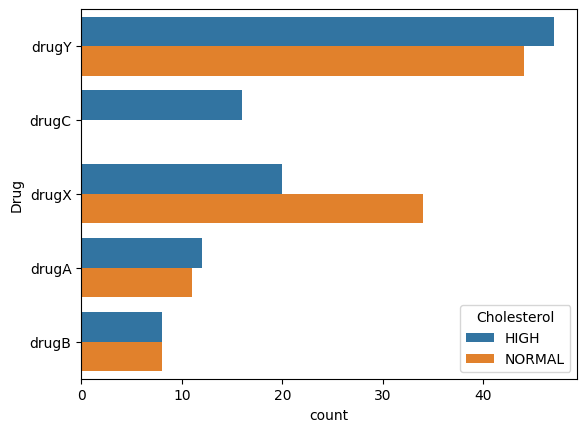

In [118]:
sns.countplot(data=df, y='Drug', hue='Cholesterol')

Berdasarkan hasil di atas:
- Drug A, B, C, Y memiliki Cholesterol yang lebih besar atau sama dibandingkan NORMAL
- Drug X Memiliki Cholesterol yang didominasi NORMAL

Pada kedua hasil plot di atas Ada pola yang mengindikasikan Bahwa kombinasi fitur BP dan Cholesterol memiliki pola yang berbeda terhadap jenis obat.

B3. Menampilkan Histogram untuk melihat distribusi data

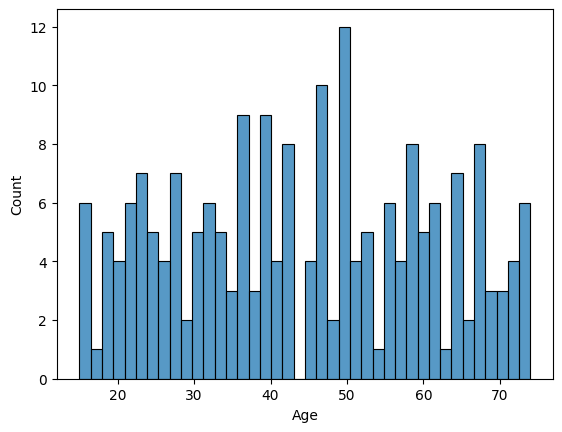

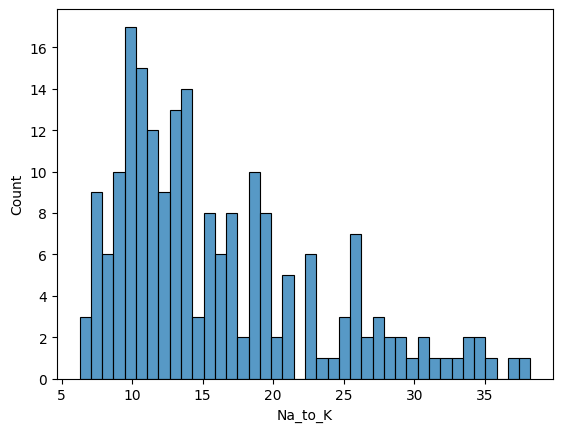

In [119]:
for i in df.select_dtypes(include=[np.number]):
    sns.histplot(df[i], bins=40)
    plt.show()

Berdasarkan hasil di atas:
- Distribusi Age relatif merata sehingga data mencakup berbagai kelompok usia.
- Distribusi kolom Na_to_K Menunjukan adanya Kemiringan ke kanan, Sehingga mengindikasikan bahwa sebagian besar data memiliki nilai relatif rendah, sementara hanya sebagian kecil data yang memiliki nilai yang lebih tinggi 
- Kedua fitur tersebut memiliki skala yang berbeda yang sebaiknya menggunakan fitur scalling untuk menyetarakan skala 2 fitur tersebut. Namun karena kami menggunakan algoritma Decision Tree, fitur scalling sudah tidak wajib di lakukan.

B4. Menampilkan boxplot untuk melihat outlier

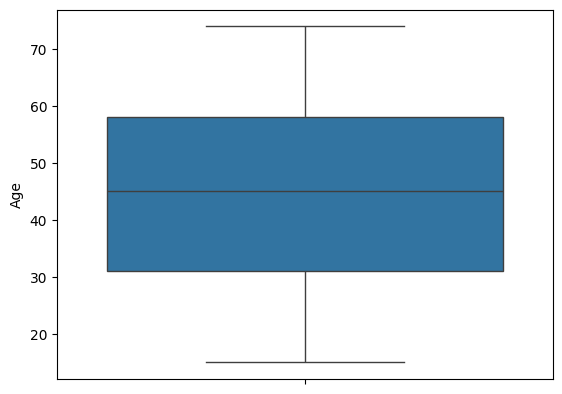

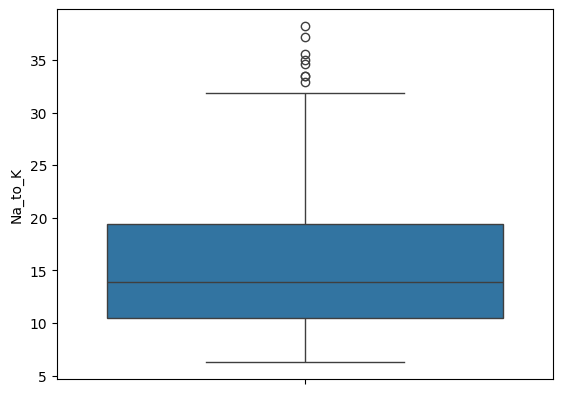

In [120]:
for i in df.select_dtypes(include=[np.number]):
    sns.boxplot(df[i])
    plt.show()

Dari hasil di atas :
- Terindikasi terdapat outlier pada fitur Na_to_K, Namun kami mengindikasikan bahwa titik-titik tersebut bukan outlier extrem sehingga kami memilih untuk tidak menangani outlier tersebut karena bisa saja titik-titik yang di anggap outlier tersebut adalah nilai yang berguna untuk klasifikasi Drug.

B5. Menampilkan distribusi kesetaraan tiap label Drug

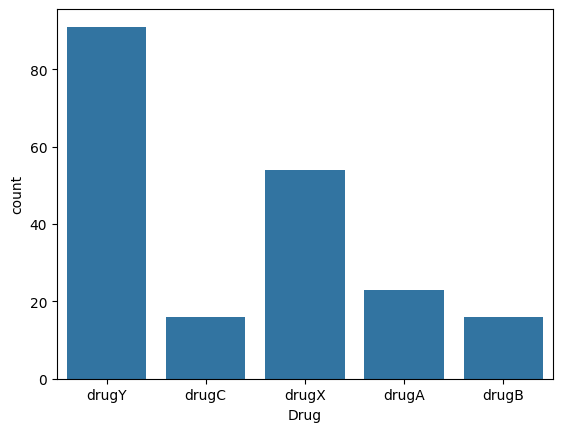

In [121]:
sns.countplot(data=df, x='Drug')
plt.show()

Berdasarkan hasil di atas kolom label memiliki ketidak seimbangan data, Hal ini dapat memengaruhi hasil klasifikasi model. Namun karena kami menggunakan algoritma Decision Tree, jumlah data setiap kelas tidak harus seimbang.

B.6 Menampilkan Pairplot

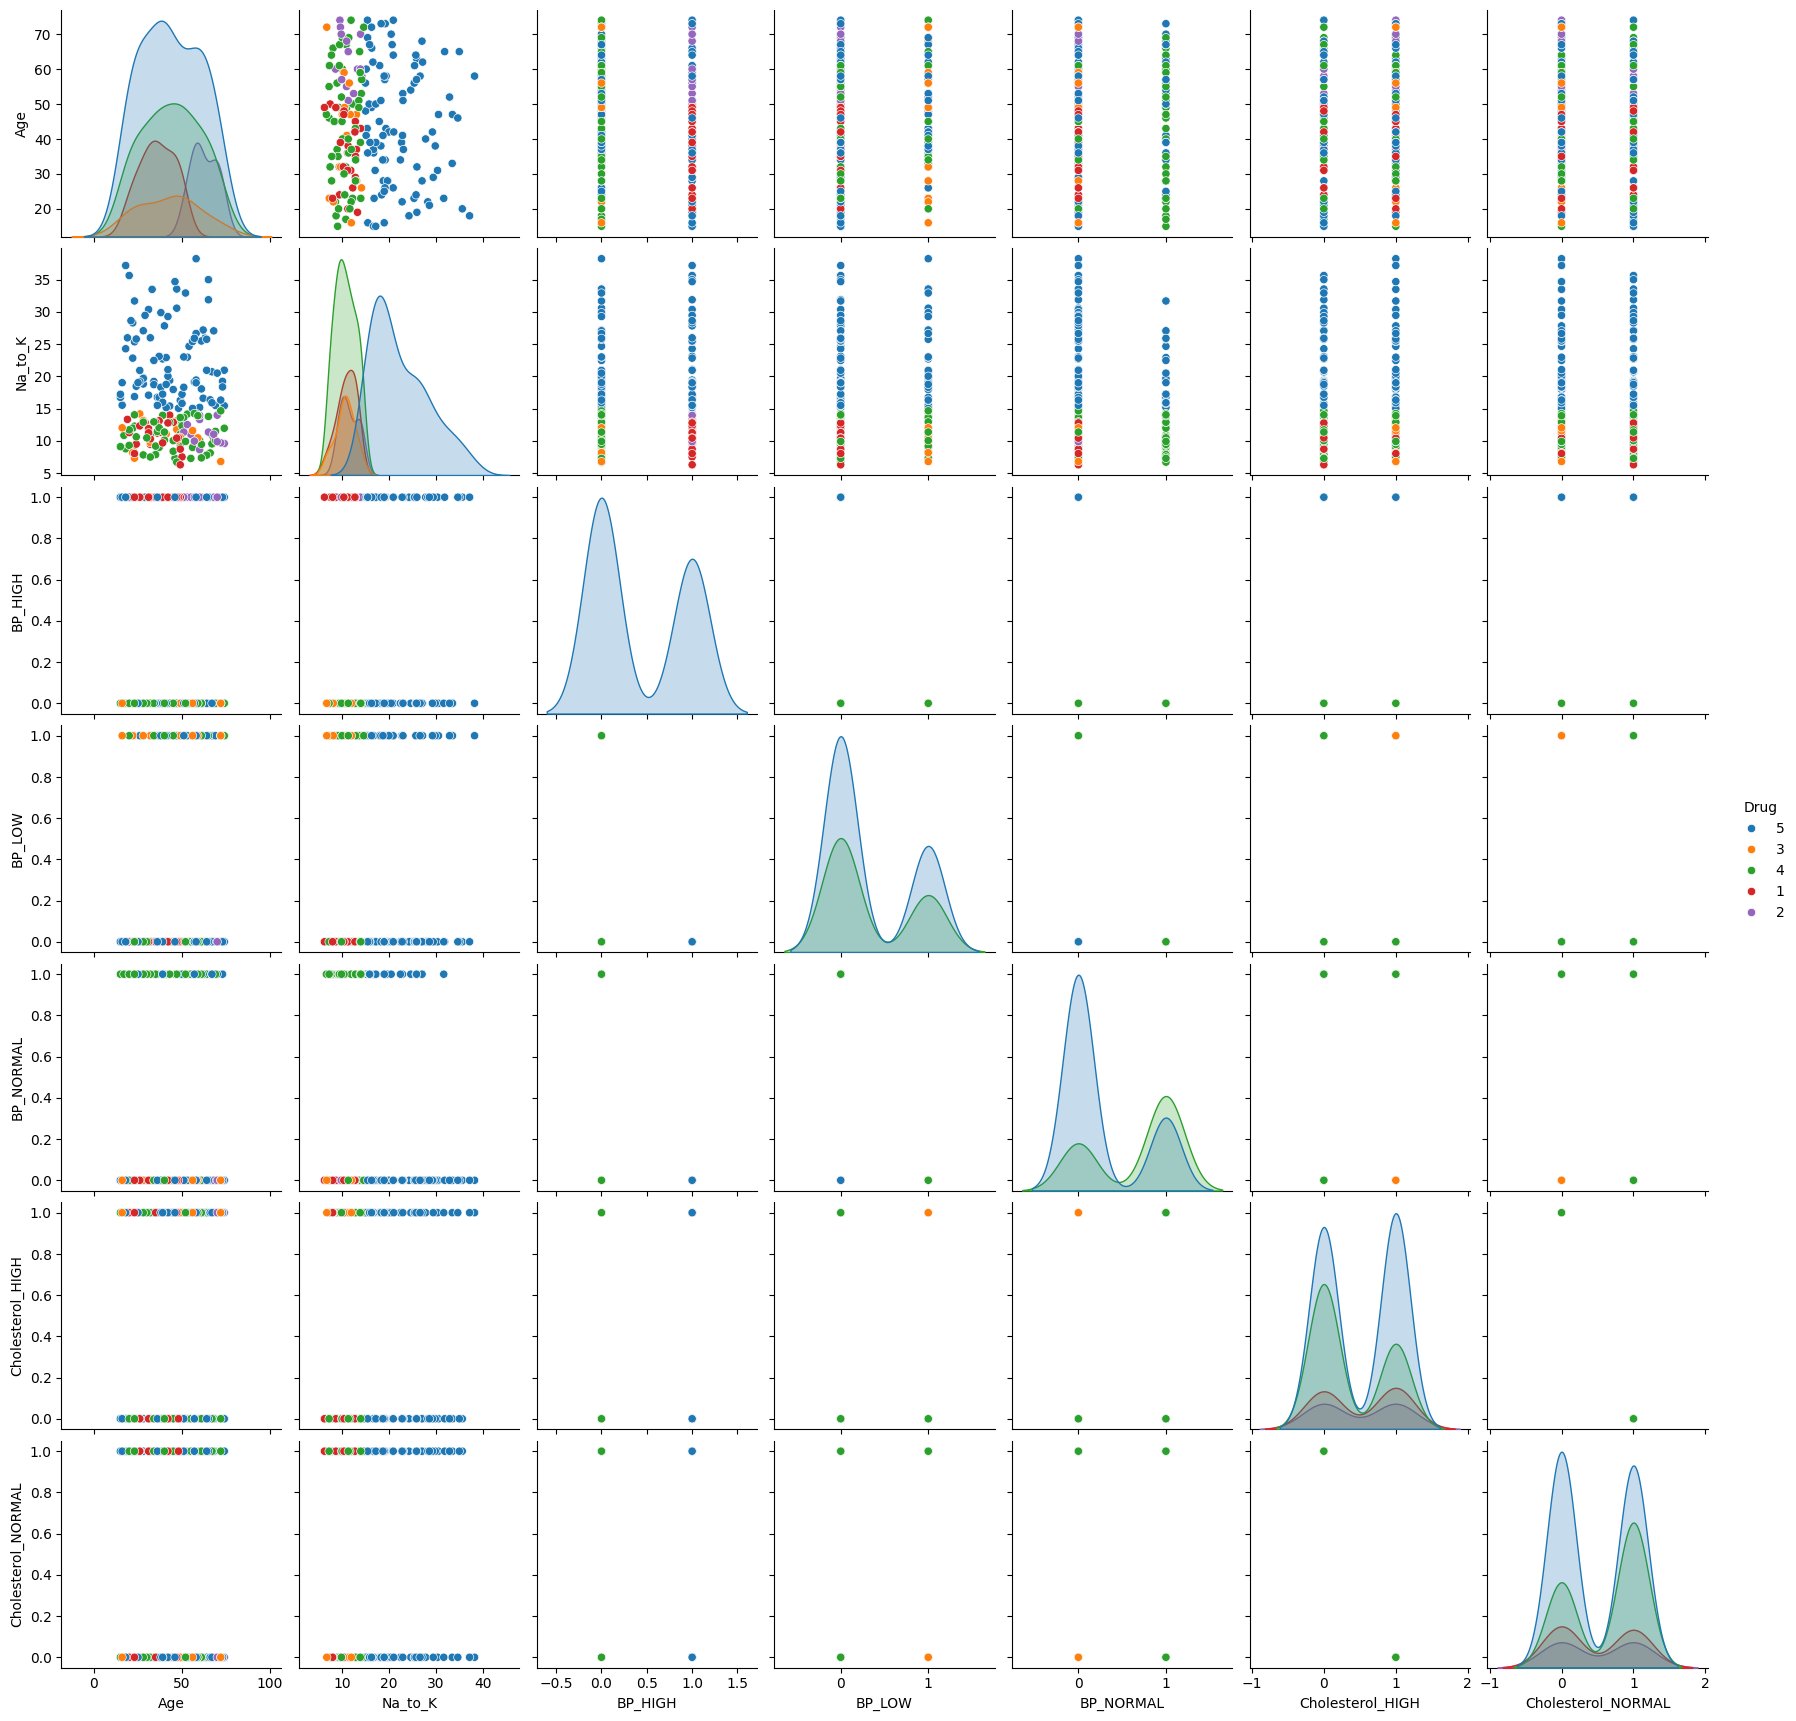

In [122]:
sns.pairplot(df_encode, hue='Drug')
plt.show()

Berdasarkan hasil di atas:
- Fitur umur terhadap semua fitur tidak memiliki perbedaan kelas Drug yang signifikan yakni tercampur
- Fitur Na_to_K terhadap semua fitur label kelas nya hampir tercampur, namun di range 20 hingga 38 memiliki indikasi semua label tersebut adalah DrugY

B7. Menampilkan Heatmap untuk menampilkan korelasi antar data

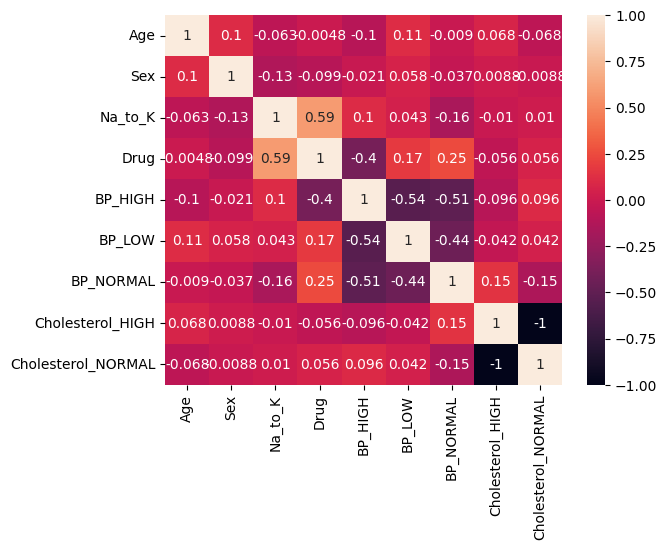

In [123]:
sns.heatmap(df_encode.corr(), annot=True)
plt.show()

Berdasarkan hasil Heatmap di atas:

- Sebagian besar fitur memiliki korelasi yang relatif rendah terhadap kelas Drug. Namun, fitur Na_to_K menunjukkan korelasi positif yang cukup kuat dengan Drug, yaitu sebesar 0,59. Selain itu, fitur BP_NORMAL dan BP_LOW memiliki korelasi masing-masing sebesar 0,25 dan 0,17 terhadap Drug.
- Antarfitur BP hasil One-Hot Encoding memiliki korelasi yang tinggi karena ketiga kolom tersebut berasal dari satu fitur yang sama. Kondisi ini dapat menyebabkan multikolinearitas. Namun, karena kami menggunakan algoritma Decision Tree yang tidak sensitif terhadap multikolinearitas, seluruh kolom tetap dipertahankan tanpa menghapus salah satunya.

## Kesimpulan EDA

Fitur Age memiliki nailai yang cukup beragam, dengan rata-rata umur rentang pada 40-an tahun. Hal ini menunjukan bahwa data mencakup berbagai kelompok usia

Fitur Age memiliki distribusi yang relatif dan tidak menunjukan kemiringan yang signifikan. Sementara itu pada fitur Na_to_K memiliki distribusi data miring ke kanan yang menunjukan bahwa sebagian besar data terkonsentrasi pada nilai yang lebih rendah

Pada pemeriksaan outlier menggunakan metode IQR, ditemukan beberapa nilai ekstrem pada fitur Na_to_K. Namun nilai tersebut tetap kami pertahankan karena kami belum mendapatkan indikasi bahwa nilai tersebut merupakan outlier, Selain itu nilai ekstrem tersebut berpotensi menyimpan informasi yang berguna dalam proses klasifikasi.

Pada visualisasi distribusi data terhadap fitur Drug, fitur Age menunjukan distribusi yang saling bercampuran antarkelas sehingga belum memperlihatkan pola yang jelas. Sebaliknya, fitur Na_to_K menunjukan pola pemisahan kelas yang lebih jelas, terutama pada nilai yang tinggi, yaitu sekitar 20 hingga 38 yang cenderung didominasi oleh kelas DrugY.

Fitur kategorikal seperti BP (Blood Presure) dan Cholesterol menunjukan adanya perbedaan distribusi pada setiap kelas obat. Salah satunya pola yang ditemukan adalah Drug 4 (DrugX) yang cenderung memiliki kategori BP LOW dan NORMAL, sedangkan distribusi Cholesterol mencakup HIGH maupun NORMAL.

Berdasarkan hasil heatmap, Fitur Na_to_K memiliki korelasi positif sebesar 0,59 terhadap label Drug, Sementara itu, fitur BP_NORMAL dan BP_LOW memiliki korelasi masing-masing sebesar 0,25 dan 0,17 terhadap Drug. Hasil One Hot Encoding BP juga memiliki hubungan linear yang tinggi karena berasal satu fitur kategorikal yang sama.

Secara keseluruhan, hasil EDA menunjukan bahwa fitur Na_to_K, BP, dan Cholesterol memiliki pola distribusi yang berpotensi membedakan kelas obat.